In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pilot = {
    "total_deliveries": 7889,
    "excluded": 1908,
    "eligible": 5981,
    "screened": 5725,
    "failed_pos": 29,
    "died_pre_echo": 2,
    "echo_completed": 27,
    "confirmed_cchd": 9,
    "confirmed_non_cchd": 10,
}

In [4]:
uptake = pilot["screened"] / pilot["eligible"]
fail_rate = pilot["failed_pos"] / pilot["screened"]
cchd_yield = pilot["confirmed_cchd"] / pilot["screened"]

print(f"Screening uptake: {uptake:.2%}")
print(f"Failed POS rate: {fail_rate:.2%}")
print(f"Observed CCHD yield: {cchd_yield:.2%}")


Screening uptake: 95.72%
Failed POS rate: 0.51%
Observed CCHD yield: 0.16%


In [5]:
def simulate_cascade(
    births,
    eligible_rate,
    pos_coverage,
    fail_rate,
    echo_completion_rate,
    true_cchd_prevalence,
    pos_sensitivity,
):
    eligible = births * eligible_rate
    screened = eligible * pos_coverage
    failed_screens = screened * fail_rate
    echo_completed = failed_screens * echo_completion_rate
    lost_before_echo = failed_screens - echo_completed

    # CCHD flow through the cascade
    true_cchd = eligible * true_cchd_prevalence
    cchd_in_screened = true_cchd * pos_coverage
    cchd_flagged_by_pos = cchd_in_screened * pos_sensitivity
    confirmed_cchd = cchd_flagged_by_pos * echo_completion_rate
    cchd_lost_pre_echo = cchd_flagged_by_pos - confirmed_cchd
    cchd_missed_false_neg = cchd_in_screened * (1 - pos_sensitivity)
    cchd_missed_unscreened = true_cchd - cchd_in_screened

    return {
        "eligible": round(eligible, 1),
        "screened": round(screened, 1),
        "failed_screens": round(failed_screens, 1),
        "echo_completed": round(echo_completed, 1),
        "lost_before_echo": round(lost_before_echo, 1),
        "true_cchd": round(true_cchd, 2),
        "confirmed_cchd": round(confirmed_cchd, 2),
        "cchd_lost_pre_echo": round(cchd_lost_pre_echo, 2),
        "cchd_missed_false_neg": round(cchd_missed_false_neg, 2),
        "cchd_missed_unscreened": round(cchd_missed_unscreened, 2),
    }

In [6]:
test_run = simulate_cascade(
    births=10000,
    eligible_rate=pilot["eligible"] / pilot["total_deliveries"],
    pos_coverage=0.96,
    fail_rate=pilot["failed_pos"] / pilot["screened"],
    echo_completion_rate=pilot["echo_completed"] / pilot["failed_pos"],
    true_cchd_prevalence=0.0022,
    pos_sensitivity=0.75,
)

for k, v in test_run.items():
    print(f"{k}: {v}")

eligible: 7581.4
screened: 7278.2
failed_screens: 36.9
echo_completed: 34.3
lost_before_echo: 2.5
true_cchd: 16.68
confirmed_cchd: 11.18
cchd_lost_pre_echo: 0.83
cchd_missed_false_neg: 4.0
cchd_missed_unscreened: 0.67


In [7]:
scenarios = {
    "Urban Tertiary": {
        "births": 10000,
        "eligible_rate": pilot["eligible"] / pilot["total_deliveries"],
        "pos_coverage": 0.96,
        "fail_rate": pilot["failed_pos"] / pilot["screened"],
        "echo_completion_rate": pilot["echo_completed"] / pilot["failed_pos"],
        "true_cchd_prevalence": 0.0022,
        "pos_sensitivity": 0.75,
    },
    "District Hospital": {
        "births": 10000,
        "eligible_rate": pilot["eligible"] / pilot["total_deliveries"],
        "pos_coverage": 0.75,
        "fail_rate": pilot["failed_pos"] / pilot["screened"],
        "echo_completion_rate": 0.60,
        "true_cchd_prevalence": 0.0022,
        "pos_sensitivity": 0.72,
    },
    "Rural / CHPS": {
        "births": 10000,
        "eligible_rate": pilot["eligible"] / pilot["total_deliveries"],
        "pos_coverage": 0.45,
        "fail_rate": pilot["failed_pos"] / pilot["screened"],
        "echo_completion_rate": 0.30,
        "true_cchd_prevalence": 0.0022,
        "pos_sensitivity": 0.70,
    },
}

results = {
    setting: simulate_cascade(**params)
    for setting, params in scenarios.items()
}

cascade_df = pd.DataFrame(results).T
cascade_df

,eligible,screened,failed_screens,echo_completed,lost_before_echo,true_cchd,confirmed_cchd,cchd_lost_pre_echo,cchd_missed_false_neg,cchd_missed_unscreened
Urban Tertiary,7581.4,7278.2,36.9,34.3,2.5,16.68,11.18,0.83,4.00,0.67
District Hospital,7581.4,5686.1,28.8,17.3,11.5,16.68,5.40,3.60,3.50,4.17
Rural / CHPS,7581.4,3411.6,17.3,5.2,12.1,16.68,1.58,3.68,2.25,9.17


In [8]:
cchd_cols = [
    "confirmed_cchd",
    "cchd_lost_pre_echo",
    "cchd_missed_false_neg",
    "cchd_missed_unscreened",
]

shares_df = cascade_df[cchd_cols].div(cascade_df["true_cchd"], axis=0) * 100
shares_df = shares_df.round(1)
shares_df

,confirmed_cchd,cchd_lost_pre_echo,cchd_missed_false_neg,cchd_missed_unscreened
Urban Tertiary,67.0,5.0,24.0,4.0
District Hospital,32.4,21.6,21.0,25.0
Rural / CHPS,9.5,22.1,13.5,55.0


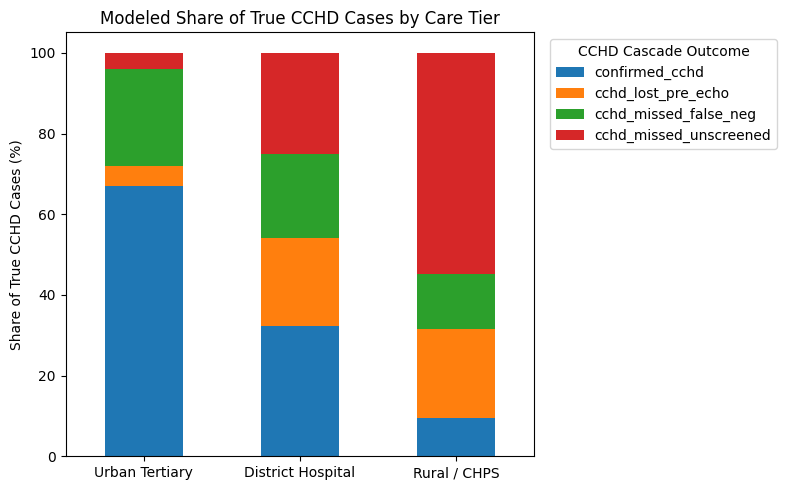

In [9]:
ax = shares_df.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
)

plt.title("Modeled Share of True CCHD Cases by Care Tier")
plt.ylabel("Share of True CCHD Cases (%)")
plt.xlabel("")
plt.xticks(rotation=0)
plt.legend(
    title="CCHD Cascade Outcome",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)
plt.tight_layout()
plt.show()

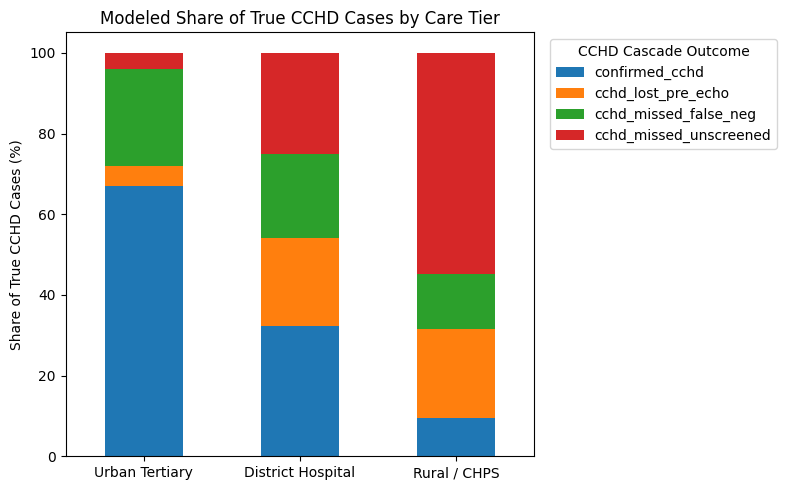

In [10]:
ax = shares_df.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
)

plt.title("Modeled Share of True CCHD Cases by Care Tier")
plt.ylabel("Share of True CCHD Cases (%)")
plt.xlabel("")
plt.xticks(rotation=0)
plt.legend(
    title="CCHD Cascade Outcome",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)
plt.tight_layout()

plt.savefig("cchd_cascade_by_care_tier.png", dpi=300, bbox_inches="tight")
plt.show()

In [11]:
cchd_sum = cascade_df[cchd_cols].sum(axis=1)
matches = np.isclose(cchd_sum, cascade_df["true_cchd"], atol=0.05)

print("Conservation check passed for all tiers:", matches.all())


Conservation check passed for all tiers: True


In [12]:
cascade_df.to_csv("cascade_counts_by_tier.csv")
shares_df.to_csv("cchd_outcome_shares_by_tier.csv")
print("Exported cascade_counts_by_tier.csv and cchd_outcome_shares_by_tier.csv")

Exported cascade_counts_by_tier.csv and cchd_outcome_shares_by_tier.csv


In [13]:
rural_base = scenarios["Rural / CHPS"]

rural_what_if = {
    "1. Rural Baseline (45% cov, 30% echo)": simulate_cascade(**rural_base),
    "2. Expand Screening Only (80% cov, 30% echo)": simulate_cascade(
        **{**rural_base, "pos_coverage": 0.80}
    ),
    "3. Expand Screening + Echo Referral (80% cov, 75% echo)": simulate_cascade(
        **{**rural_base, "pos_coverage": 0.80, "echo_completion_rate": 0.75}
    ),
}

what_if_df = pd.DataFrame(rural_what_if).T
what_if_shares = (
    what_if_df[cchd_cols].div(what_if_df["true_cchd"], axis=0) * 100
).round(1)

what_if_shares

,confirmed_cchd,cchd_lost_pre_echo,cchd_missed_false_neg,cchd_missed_unscreened
"1. Rural Baseline (45% cov, 30% echo)",9.5,22.1,13.5,55.0
"2. Expand Screening Only (80% cov, 30% echo)",16.8,39.2,24.0,20.0
"3. Expand Screening + Echo Referral (80% cov, 75% echo)",42.0,14.0,24.0,20.0


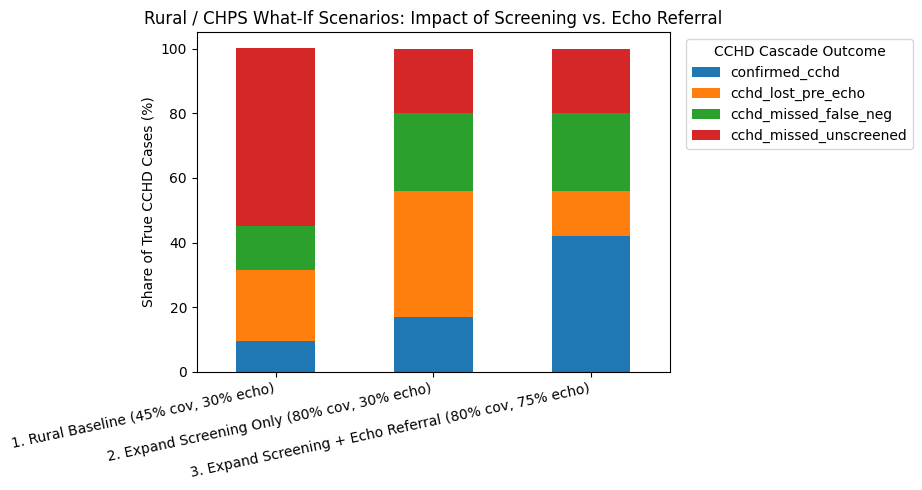

In [14]:
what_if_shares.to_csv("rural_what_if_shares.csv")

ax = what_if_shares.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
)

plt.title("Rural / CHPS What-If Scenarios: Impact of Screening vs. Echo Referral")
plt.ylabel("Share of True CCHD Cases (%)")
plt.xlabel("")
plt.xticks(rotation=12, ha="right")
plt.legend(
    title="CCHD Cascade Outcome",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)
plt.tight_layout()

plt.savefig("rural_what_if_cascade.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
ghana-chd-screening-equity/
├── notebooks/
│   └── chd_screening_cascade.ipynb
├── results/
│   ├── figures/
│   │   ├── cchd_cascade_by_care_tier.png
│   │   └── rural_what_if_cascade.png
│   └── tables/
│       ├── cascade_counts_by_tier.csv
│       ├── cchd_outcome_shares_by_tier.csv
│       └── rural_what_if_shares.csv
├── requirements.txt
└── README.md